# Truncation Study — Stages 2 and 3

This notebook completes the experimental programme. It sweeps the truncation
point across its full grid for all three models and answers the two remaining
research questions.

**Stage 2 — preset against learned.** The proposed model and the Liquid State
Machine share a substrate exactly: the same neurons, the same connectivity, the
same initialization, the same neuron parameters. They differ in one respect only,
whether the reservoir is adapted by truncated surrogate-gradient descent, so the
difference between their curves measures what a short window of learning
recovers from a mathematically cheap initialization.

**Stage 3 — edge viability.** The proposed model is compared against a dense
LSTM of matched trainable capacity on classification quality, operation counts
and estimated energy.

The truncation point is swept rather than selected. A single best $k$ would
conceal the shape of the curve, and that shape is the result. Critically, the
LSTM is swept over the identical grid: a flat accuracy-versus-$k$ curve for the
spiking model alone would admit two explanations, and only sweeping the dense
baseline as well separates *the architecture tolerates truncation* from *the data
permits early classification*. The model-free prefix curves from Notebook 02
provide the third reference point.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from edgesnn.data_utils import make_datasets
from edgesnn.experiments import k_values, load_config, run_grid, seeds_for
from edgesnn.plotting import plot_confusion_matrix, plot_prefix_curve
from edgesnn.temporal_analysis import prefix_classifier_curve

DATA_DIR = "../Data"
FIG_DIR = "../reports/figures"
DATASETS = ["ECG5000", "Wafer", "InsectSound"]
N_SEEDS = 5

# Every initializer is swept across the whole truncation grid, on BOTH the
# trained and the frozen reservoir. Stage 1 identifies no single best cheap
# generator -- the ranking differs by dataset and the seed spread is as large as
# the differences -- so nominating one to carry the truncation study would make
# every result downstream depend on an arbitrary pick. Sweeping all five removes
# the choice instead of defending it, and makes each comparison like-for-like:
# the trained and frozen curves at a given initializer differ in exactly one
# respect, which is what Stage 2 requires.
INIT_METHODS = ["gaussian", "lcg", "lfsr", "sobol", "halton"]

# The initializer used where the figure compares ARCHITECTURES rather than
# initializers. Gaussian is the reference the study is defined against, so the
# architectural comparison is stated there and is unaffected by any cheap-
# generator choice.
REFERENCE_INIT = "gaussian"

splits = {name: make_datasets(DATA_DIR, name) for name in DATASETS}
for name, (train_ds, _) in splits.items():
    print(f"{name:<12} T={train_ds.seq_len:>4}  k grid = {k_values(train_ds.seq_len)}")

ECG5000      T= 140  k grid = [28, 56, 84, 112, 140]
Wafer        T= 152  k grid = [30, 61, 91, 122, 152]
InsectSound  T= 600  k grid = [120, 240, 360, 480, 600]


## 1. The sweep

Every truncation point is run under eleven conditions: the proposed model and
the Liquid State Machine under each of the five initializers, and the LSTM, which
has no reservoir to initialize. Sweeping both spiking models over the same five
generators means the trained and the frozen curve at any given initializer differ
in exactly one respect, so Stage 2 may be read at each of them rather than at one
nominated in advance; the LSTM supplies Stage 3.

Every condition uses the configuration frozen in Notebook 03. Nothing is re-tuned
per $k$ — doing so would fold tuning effects into the curve and make it
unreadable as a truncation result.

In [2]:
sweep = {}

for name, (train_ds, test_ds) in splits.items():
    snn_cfg = load_config(f"config_snn_{name}")
    lsm_cfg = load_config(f"config_lsm_{name}")
    lstm_cfg = load_config(f"config_lstm_{name}")
    if snn_cfg is None or lsm_cfg is None or lstm_cfg is None:
        raise RuntimeError(f"Run notebook 03 first — configurations missing for {name}.")

    conditions = []
    for k in k_values(train_ds.seq_len):
        for method in INIT_METHODS:
            conditions += [dict(kind="snn", k=k, init_method=method, seed=s,
                                config=dict(snn_cfg))
                           for s in seeds_for(method, N_SEEDS)]
            conditions += [dict(kind="lsm", k=k, init_method=method, seed=s,
                                config=dict(lsm_cfg))
                           for s in seeds_for(method, N_SEEDS)]
        # The LSTM has no reservoir, so it is run once per k, not once per
        # initializer; its rows are recorded under the name `default`.
        conditions += [dict(kind="lstm", k=k, seed=s, config=dict(lstm_cfg))
                       for s in range(N_SEEDS)]

    sweep[name] = run_grid(f"truncation_{name}", conditions, train_ds, test_ds)

truncation_ECG5000: 275 conditions to run


truncation_ECG5000:   0%|          | 0/275 [00:00<?, ?run/s]

truncation_Wafer: 275 conditions to run


truncation_Wafer:   0%|          | 0/275 [00:00<?, ?run/s]

truncation_InsectSound: 275 conditions to run


truncation_InsectSound:   0%|          | 0/275 [00:00<?, ?run/s]

In [3]:
def curves_by_condition(frame, seq_len):
    """Group a sweep into one curve per (model, initializer), averaged over seeds."""
    frame = frame.copy()
    frame["condition"] = frame.apply(
        lambda r: r.model.upper() if r.model == "lstm"
        else f"{r.model.upper()} · {r.init_method}", axis=1)
    out = {}
    for label, group in frame.groupby("condition"):
        curve = (group.groupby("k")
                 .agg(macro_f1_mean=("macro_f1", "mean"),
                      macro_f1_std=("macro_f1", "std"),
                      energy_pj=("energy_pj", "mean"),
                      sops=("sops", "mean"), macs=("macs", "mean"))
                 .reset_index())
        curve["macro_f1_std"] = curve.macro_f1_std.fillna(0.0)
        curve["fraction"] = curve.k / seq_len
        out[label] = curve
    return out

model_curves = {name: curves_by_condition(frame, splits[name][0].seq_len)
                for name, frame in sweep.items()}

# Three views of the same sweep. All eleven curves on one axis would be
# unreadable and would also conflate two questions -- which architecture, and
# which initializer -- so each figure below answers exactly one of them.
ARCHITECTURES = [f"SNN · {REFERENCE_INIT}", f"LSM · {REFERENCE_INIT}", "LSTM"]
SNN_BY_INIT = [f"SNN · {m}" for m in INIT_METHODS]
LSM_BY_INIT = [f"LSM · {m}" for m in INIT_METHODS]

for name, curves in model_curves.items():
    print(f"{name}: {len(curves)} conditions — {', '.join(curves)}")

ECG5000: 11 conditions — LSM · gaussian, LSM · halton, LSM · lcg, LSM · lfsr, LSM · sobol, LSTM, SNN · gaussian, SNN · halton, SNN · lcg, SNN · lfsr, SNN · sobol
Wafer: 11 conditions — LSM · gaussian, LSM · halton, LSM · lcg, LSM · lfsr, LSM · sobol, LSTM, SNN · gaussian, SNN · halton, SNN · lcg, SNN · lfsr, SNN · sobol
InsectSound: 11 conditions — LSM · gaussian, LSM · halton, LSM · lcg, LSM · lfsr, LSM · sobol, LSTM, SNN · gaussian, SNN · halton, SNN · lcg, SNN · lfsr, SNN · sobol


## 2. Accuracy against the truncation point

Each panel overlays the model curves on the model-free prefix-classifier curve
recomputed from Notebook 02. The probe carries no recurrence and no temporal
inductive bias, so it is a floor rather than a competitor: a model tracking it
closely has demonstrated nothing that a linear classifier on raw amplitudes could
not, whereas the margin above it is what the architecture has earned.

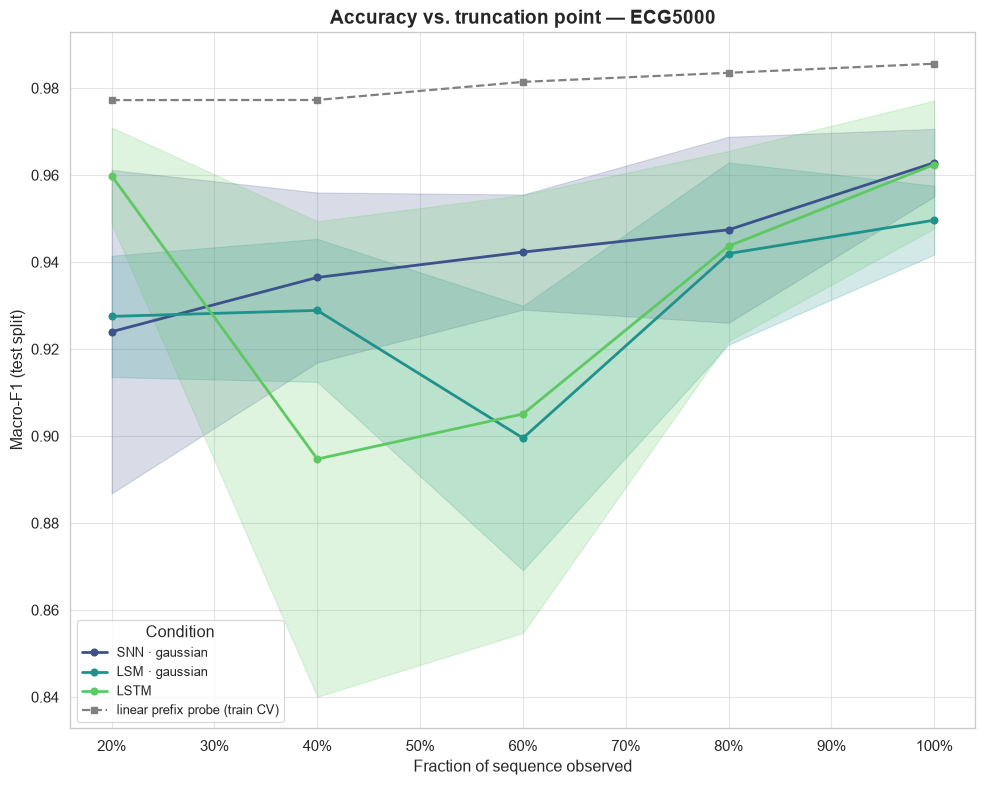

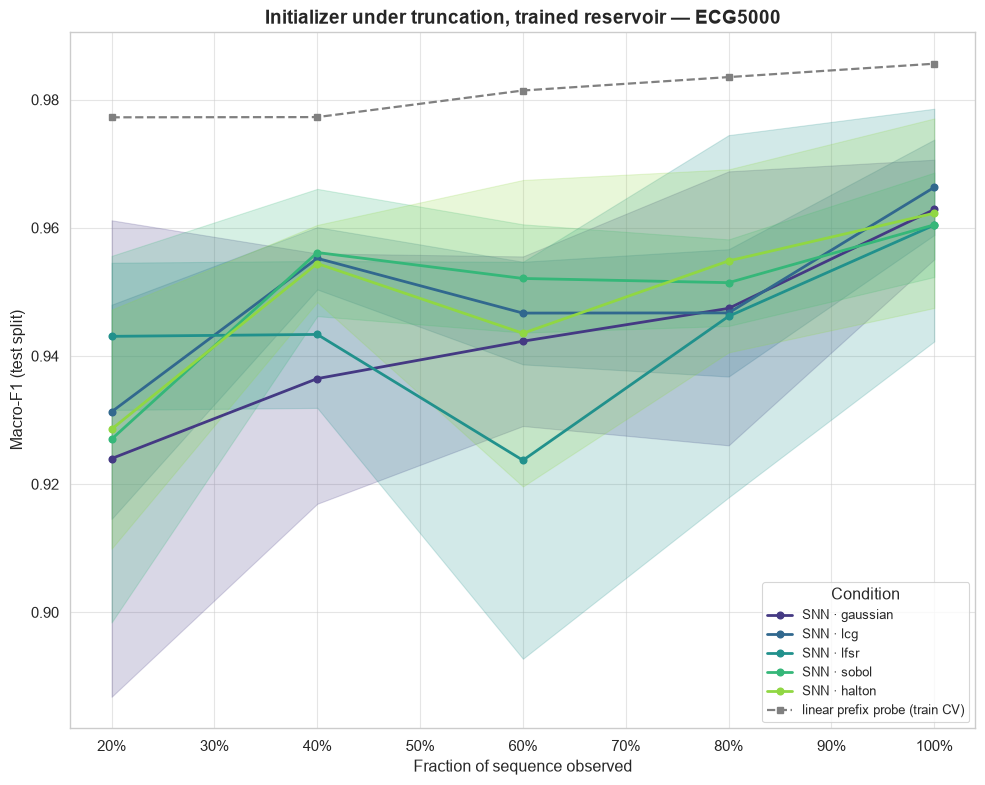

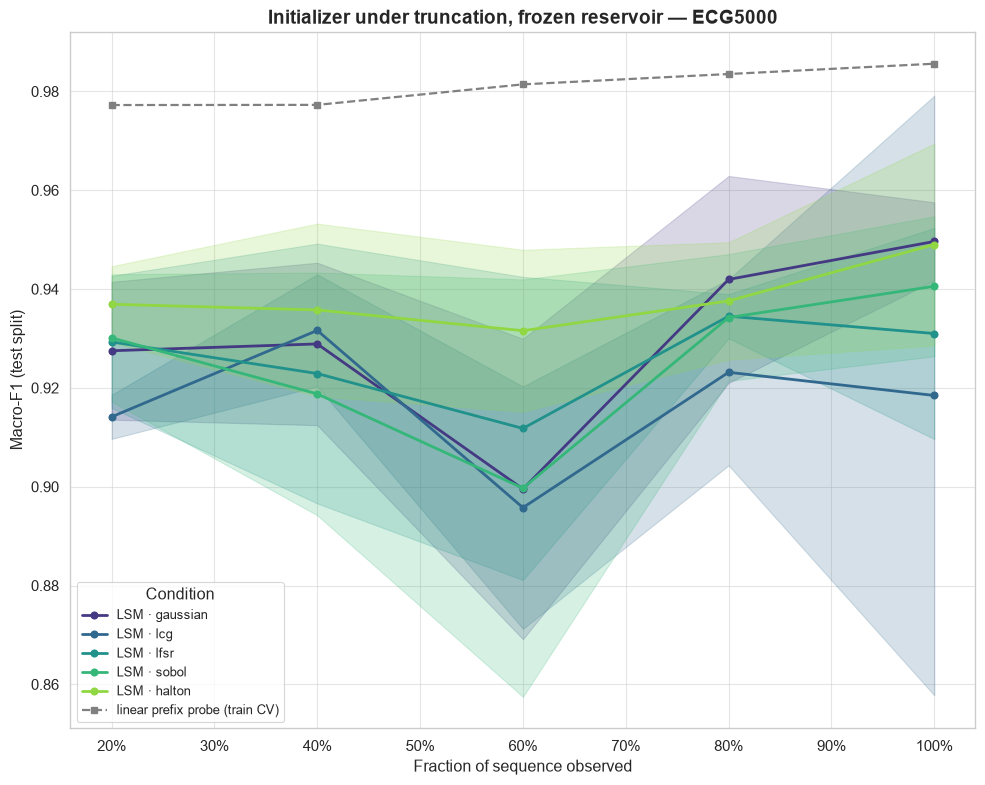

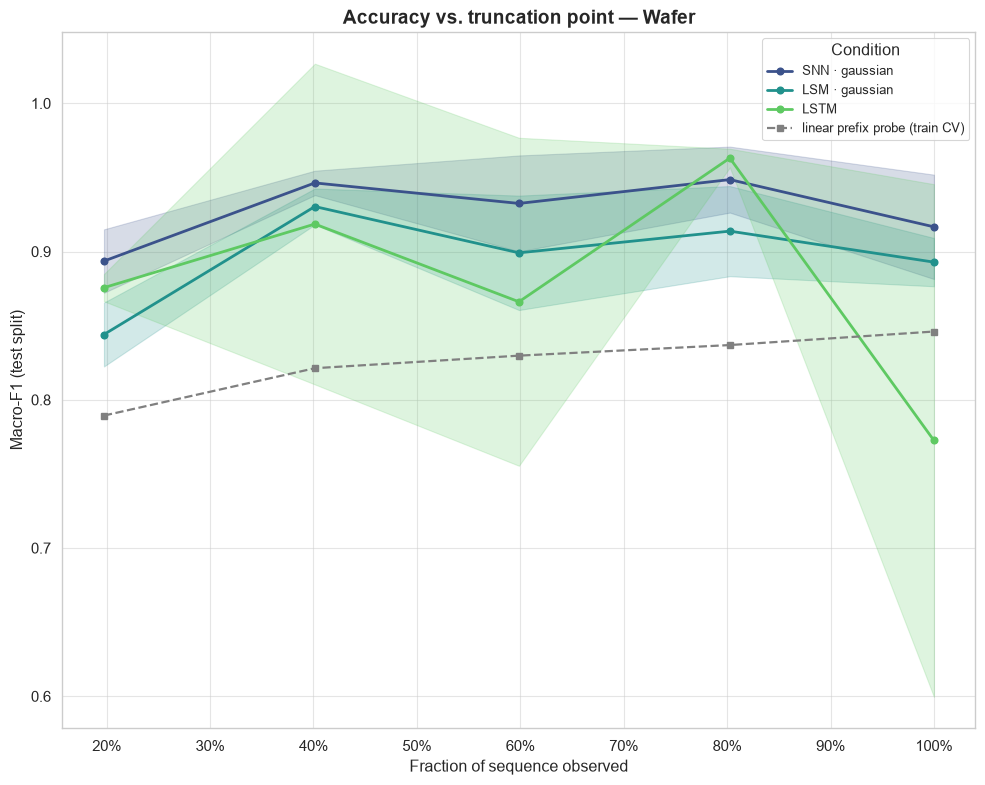

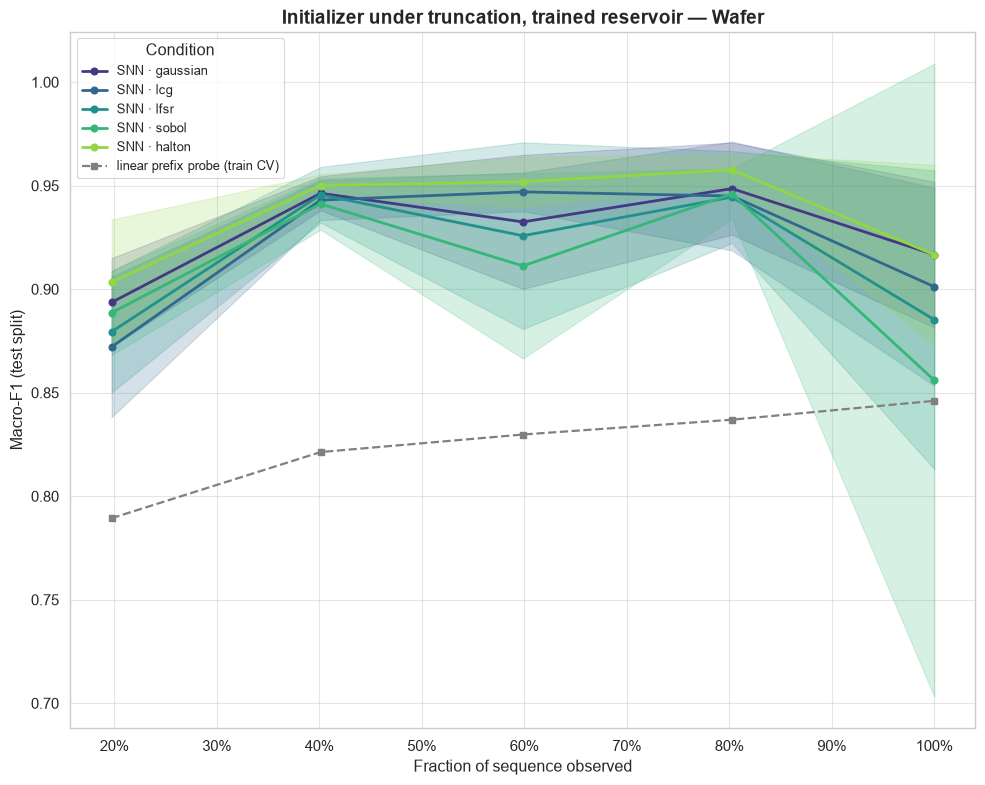

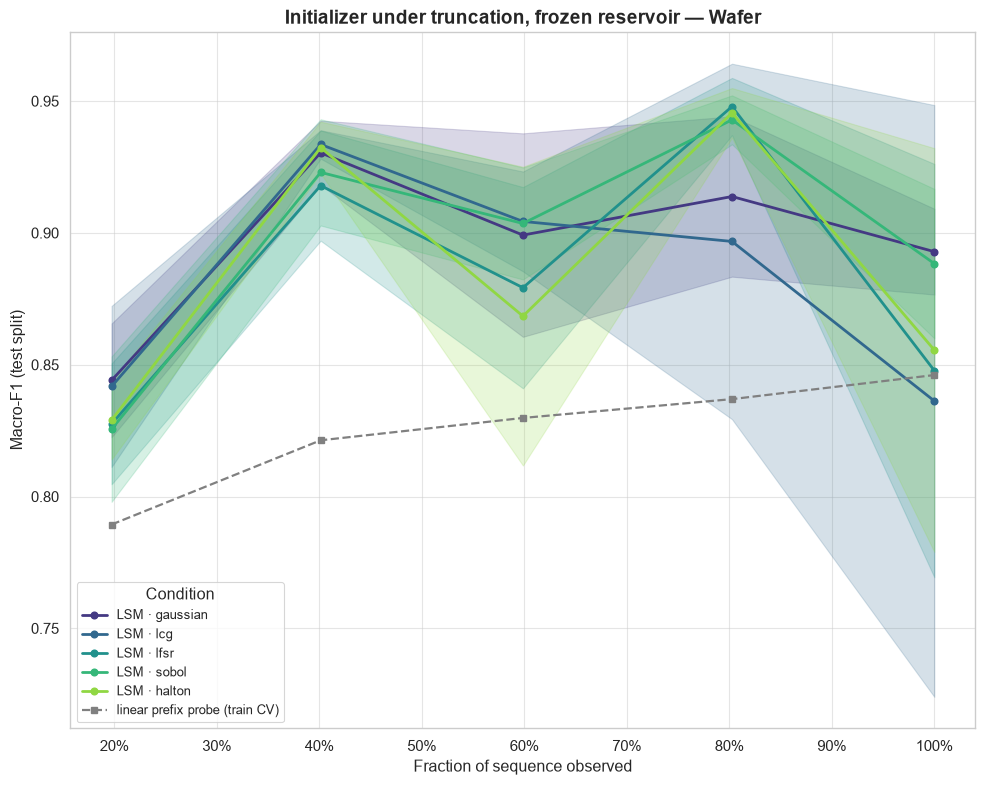

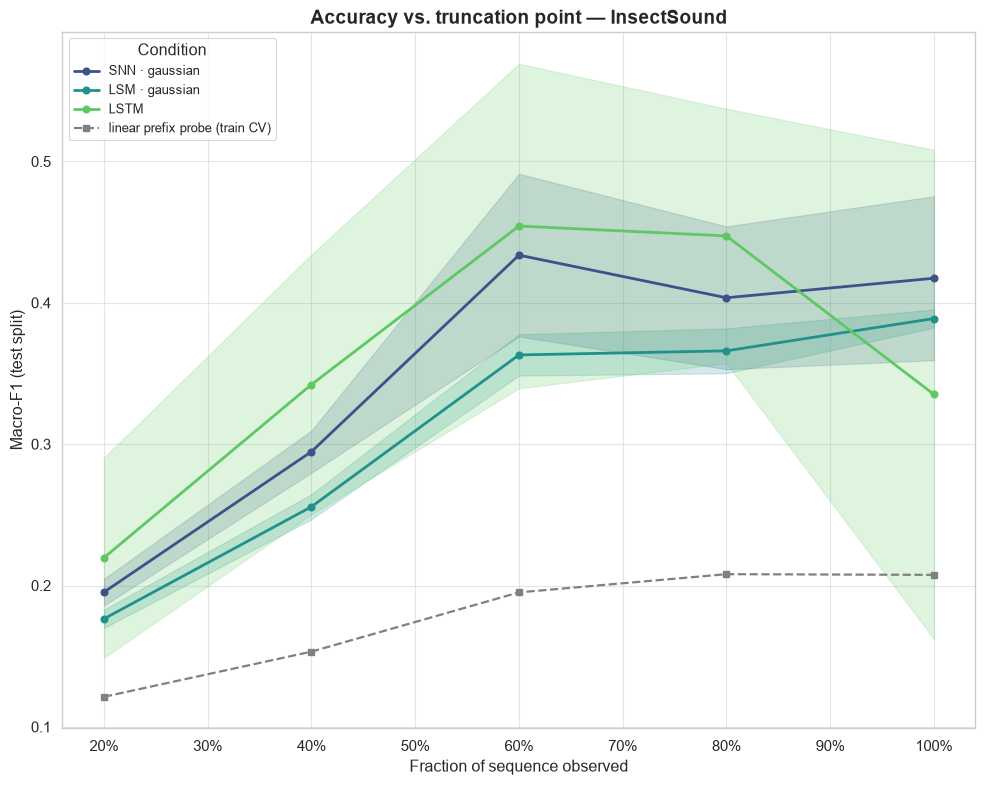

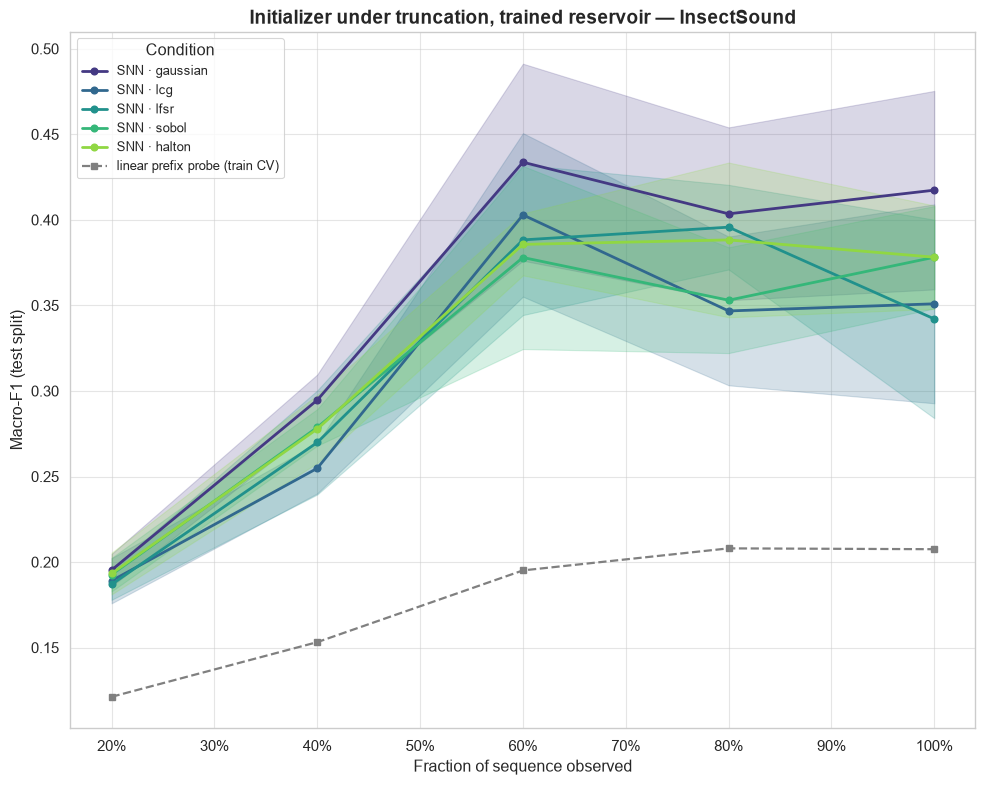

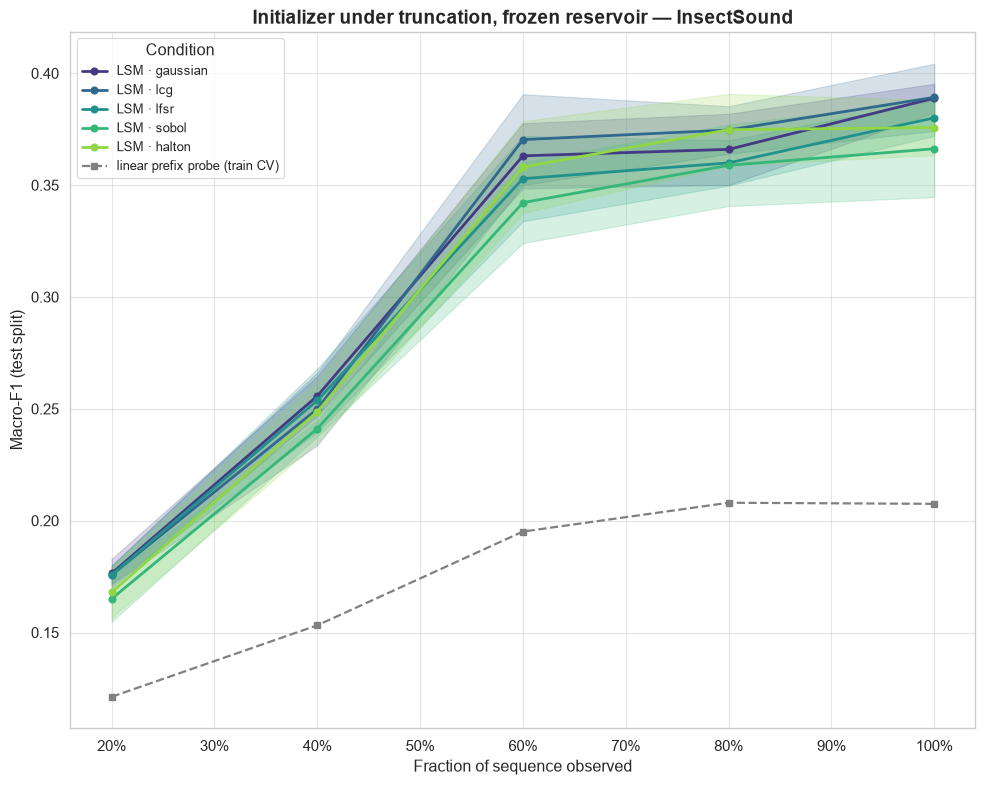

In [9]:
for name, (train_ds, _) in splits.items():
    probe = prefix_classifier_curve(train_ds.x, train_ds.y, seed=0)

    def panel(subset, title, filename):
        fig, ax = plt.subplots(figsize=(10, 8))
        plot_prefix_curve({label: model_curves[name][label] for label in subset
                           if label in model_curves[name]},
                          x="fraction", ax=ax, title=title,
                          ylabel="Macro-F1 (test split)", legend_title="Condition")
        ax.plot(probe.fraction, probe.macro_f1_mean, linestyle="--", color="grey",
                marker="s", markersize=4, linewidth=1.6,
                label="linear prefix probe (train CV)")
        ax.legend(title="Condition", fontsize=9)
        fig.tight_layout()
        fig.savefig(f"{FIG_DIR}/{filename}", dpi=300, bbox_inches="tight")
        plt.show()

    # Which architecture, at the reference initializer.
    panel(ARCHITECTURES, f"Accuracy vs. truncation point — {name}",
          f"{name}_truncation_curve.png")
    # Which initializer, on the trained reservoir.
    panel(SNN_BY_INIT, f"Initializer under truncation, trained reservoir — {name}",
          f"{name}_truncation_snn_by_init.png")
    # Which initializer, on the frozen reservoir.
    panel(LSM_BY_INIT, f"Initializer under truncation, frozen reservoir — {name}",
          f"{name}_truncation_lsm_by_init.png")


## 3. Stage 2 — how much does training recover?

The proposed model and the LSM are isolated here under the same cheap
initializer. Their difference at each $k$ is the contribution of truncated
surrogate-gradient learning, with every other factor held identical by
construction.

In [5]:
for name, curves in model_curves.items():
    print(f"\n{name} — Stage 2: effect of training the reservoir, by initializer")
    rows = []
    for method in INIT_METHODS:
        trained, frozen = curves.get(f"SNN · {method}"), curves.get(f"LSM · {method}")
        if trained is None or frozen is None:
            continue
        trained, frozen = trained.set_index("k"), frozen.set_index("k")
        rows.append(pd.DataFrame({
            "init": method,
            "fraction": trained.fraction,
            "trained (SNN)": trained.macro_f1_mean,
            "frozen (LSM)": frozen.macro_f1_mean,
            "recovered by training": trained.macro_f1_mean - frozen.macro_f1_mean,
            "energy ratio": trained.energy_pj / frozen.energy_pj,
        }))
    display(pd.concat(rows).reset_index().round(4))



ECG5000 — Stage 2: effect of training the reservoir, by initializer


,k,init,fraction,trained (SNN),frozen (LSM),recovered by training,energy ratio
0,28,gaussian,0.2,0.9240,0.9275,-0.0035,0.9453
1,56,gaussian,0.4,0.9365,0.9289,0.0076,0.9318
2,84,gaussian,0.6,0.9423,0.8995,0.0428,0.8825
3,112,gaussian,0.8,0.9474,0.9420,0.0055,0.8890
4,140,gaussian,1.0,0.9629,0.9496,0.0132,0.8984
5,28,lcg,0.2,0.9313,0.9141,0.0171,0.9607
6,56,lcg,0.4,0.9553,0.9316,0.0236,0.9219
7,84,lcg,0.6,0.9467,0.8958,0.0509,0.8994
8,112,lcg,0.8,0.9467,0.9232,0.0236,0.9145
9,140,lcg,1.0,0.9663,0.9185,0.0479,0.9046



Wafer — Stage 2: effect of training the reservoir, by initializer


,k,init,fraction,trained (SNN),frozen (LSM),recovered by training,energy ratio
0,30,gaussian,0.1974,0.8936,0.8441,0.0495,0.9566
1,61,gaussian,0.4013,0.9464,0.9304,0.0159,0.9398
2,91,gaussian,0.5987,0.9325,0.8992,0.0333,0.9422
3,122,gaussian,0.8026,0.9486,0.9138,0.0348,0.9350
4,152,gaussian,1.0000,0.9167,0.8929,0.0238,0.9396
5,30,lcg,0.1974,0.8721,0.8418,0.0304,0.9641
6,61,lcg,0.4013,0.9431,0.9336,0.0095,0.9563
7,91,lcg,0.5987,0.9470,0.9044,0.0426,0.9245
8,122,lcg,0.8026,0.9450,0.8968,0.0482,0.9664
9,152,lcg,1.0000,0.9012,0.8363,0.0649,0.9625



InsectSound — Stage 2: effect of training the reservoir, by initializer


,k,init,fraction,trained (SNN),frozen (LSM),recovered by training,energy ratio
0,120,gaussian,0.2,0.1953,0.1764,0.0189,0.9650
1,240,gaussian,0.4,0.2947,0.2557,0.0390,0.9565
2,360,gaussian,0.6,0.4337,0.3631,0.0706,0.9426
3,480,gaussian,0.8,0.4036,0.3660,0.0375,0.9498
4,600,gaussian,1.0,0.4174,0.3889,0.0285,0.9513
5,120,lcg,0.2,0.1891,0.1757,0.0133,0.9620
6,240,lcg,0.4,0.2548,0.2499,0.0049,0.9733
7,360,lcg,0.6,0.4029,0.3704,0.0326,0.9540
8,480,lcg,0.8,0.3468,0.3747,-0.0279,0.9529
9,600,lcg,1.0,0.3510,0.3893,-0.0383,0.9678


The energy ratio is reported beside the accuracy difference because the two
models run on the same substrate: any accuracy that training buys is bought at
whatever change it produces in the firing rate, and a ratio near unity means the
improvement was effectively free at inference time.

## 4. Stage 3 — accuracy against energy

The efficiency claim is a trade-off, so it is plotted as one. Each point is a
model at one truncation point; the horizontal axis is estimated arithmetic energy
per inference on a logarithmic scale, the vertical axis Macro-F1. A model lying
up and to the left dominates one lying down and to the right.

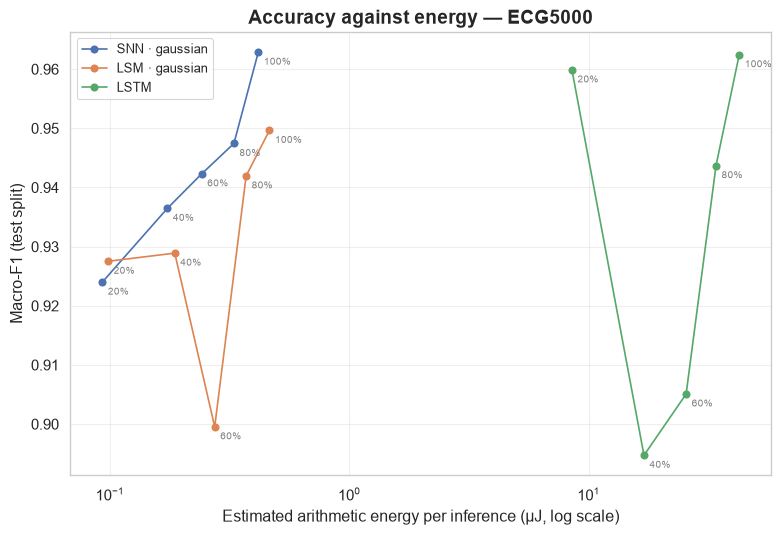

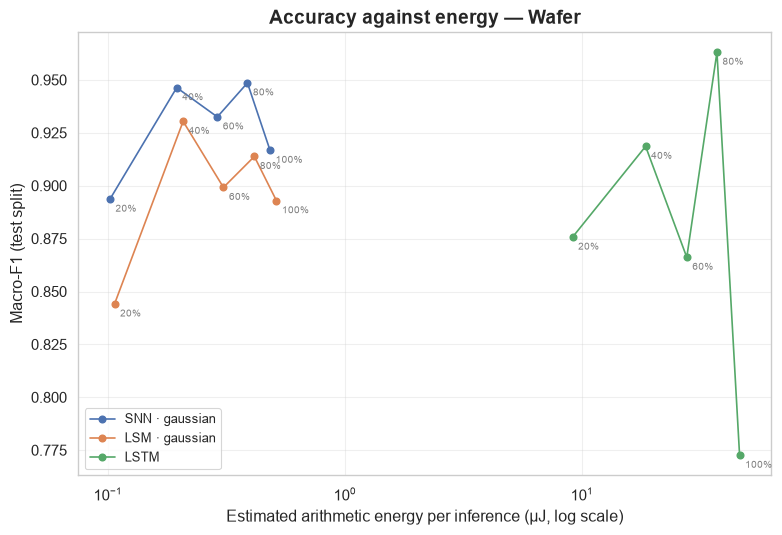

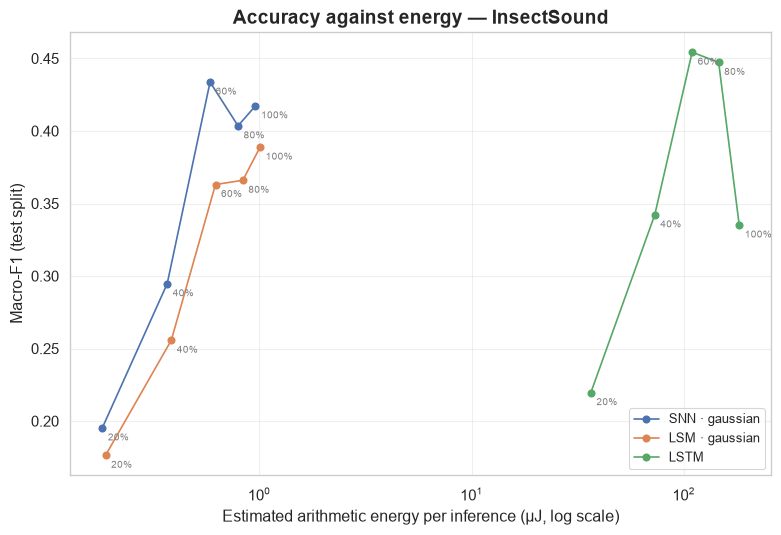

In [6]:
for name, curves in model_curves.items():
    fig, ax = plt.subplots(figsize=(8, 5.5))
    # Restricted to the architectural comparison: an SNN's energy barely moves
    # with the initializer, so five near-identical curves would overplot and
    # hide the gap between architectures that this figure exists to show.
    for label in ARCHITECTURES:
        curve = curves[label]
        ax.plot(curve.energy_pj / 1e6, curve.macro_f1_mean, marker="o", label=label)
        for _, row in curve.iterrows():
            ax.annotate(f"{row.fraction:.0%}", (row.energy_pj / 1e6, row.macro_f1_mean),
                        textcoords="offset points", xytext=(4, -9), fontsize=7.5,
                        color="grey")
    ax.set_xscale("log")
    ax.set_xlabel("Estimated arithmetic energy per inference (µJ, log scale)")
    ax.set_ylabel("Macro-F1 (test split)")
    ax.set_title(f"Accuracy against energy — {name}", fontsize=14, fontweight="bold")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/{name}_energy_tradeoff.png", dpi=300, bbox_inches="tight")
    plt.show()

In [7]:
headline = []
for name, curves in model_curves.items():
    lstm_full = curves["LSTM"].sort_values("k").iloc[-1]
    for label, curve in curves.items():
        best = curve.loc[curve.macro_f1_mean.idxmax()]
        headline.append({
            "dataset": name, "condition": label,
            "best k": int(best.k), "of T": f"{best.fraction:.0%}",
            "macro_f1": best.macro_f1_mean,
            "energy_uJ": best.energy_pj / 1e6,
            "energy vs full LSTM": lstm_full.energy_pj / best.energy_pj,
            "F1 vs full LSTM": best.macro_f1_mean - lstm_full.macro_f1_mean,
        })

headline = pd.DataFrame(headline)
display(headline.round(4))
headline.to_csv("../reports/results/headline_summary.csv", index=False)

,dataset,condition,best k,of T,macro_f1,energy_uJ,energy vs full LSTM,F1 vs full LSTM
0,ECG5000,LSM · gaussian,140,100%,0.9496,0.4633,91.8189,-0.0128
1,ECG5000,LSM · halton,140,100%,0.9490,0.4607,92.3359,-0.0134
2,ECG5000,LSM · lcg,56,40%,0.9316,0.1912,222.4727,-0.0308
3,ECG5000,LSM · lfsr,112,80%,0.9345,0.3833,110.9788,-0.0279
4,ECG5000,LSM · sobol,140,100%,0.9406,0.4625,91.9796,-0.0219
5,ECG5000,LSTM,140,100%,0.9624,42.5361,1.0000,0.0000
6,ECG5000,SNN · gaussian,140,100%,0.9629,0.4162,102.1982,0.0004
7,ECG5000,SNN · halton,140,100%,0.9623,0.4191,101.4904,-0.0002
8,ECG5000,SNN · lcg,140,100%,0.9663,0.4193,101.4502,0.0039
9,ECG5000,SNN · lfsr,140,100%,0.9604,0.4403,96.6088,-0.0020


## 5. Error structure at the operating point

Scalar metrics say how much accuracy a truncated model gives up but not *where*.
A model that degrades by collapsing one class into another is a qualitatively
different outcome from one that degrades uniformly, and on an imbalanced
fault-detection task the distinction decides whether the model is usable at all.

ECG5000: k=56 (40%), Macro-F1 0.9575, accuracy 0.9591 (majority floor 0.5838)
[plot] saved ../reports/figures/ECG5000_confusion_gaussian_k56.png


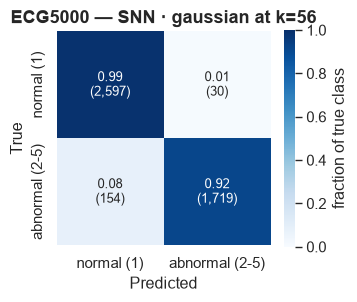

Wafer: k=61 (40%), Macro-F1 0.9560, accuracy 0.9828 (majority floor 0.8921)
[plot] saved ../reports/figures/Wafer_confusion_gaussian_k61.png


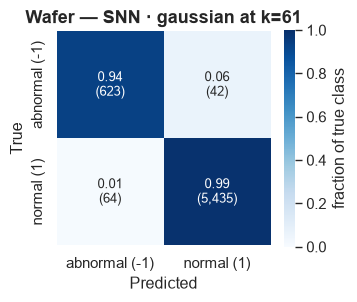

InsectSound: k=240 (40%), Macro-F1 0.3317, accuracy 0.3317 (majority floor 0.1000)
[plot] saved ../reports/figures/InsectSound_confusion_gaussian_k240.png


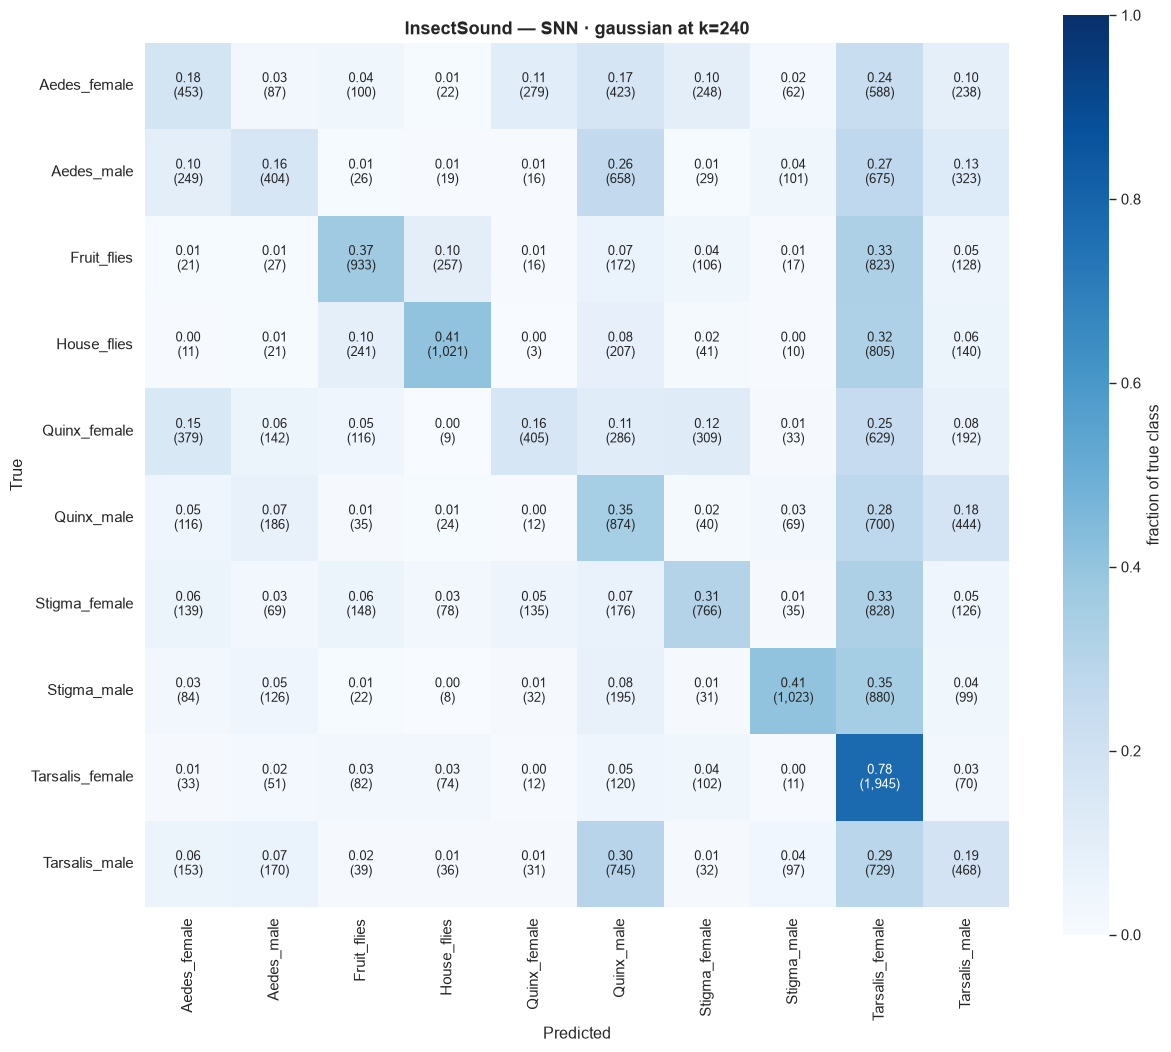

In [8]:
from edgesnn.evaluation_metrics import evaluate_efficiency
from edgesnn.experiments import build_model
from edgesnn.training import train_model

OPERATING_FRACTION = 0.4      # the cutoff to characterise; read it off Section 2

for name, (train_ds, test_ds) in splits.items():
    k = k_values(train_ds.seq_len)[int(OPERATING_FRACTION * 5) - 1]
    config = dict(load_config(f"config_snn_{name}"))
    lr = config.pop("lr")

    model = build_model("snn", num_classes=train_ds.num_classes, k=k,
                        init_method=REFERENCE_INIT, seed=0, **config)
    train_model(model, train_ds, lr=lr, seed=0, progress=False)
    metrics = evaluate_efficiency(model, test_ds, k=k)

    print(f"{name}: k={k} ({k / train_ds.seq_len:.0%}), "
          f"Macro-F1 {metrics['macro_f1']:.4f}, accuracy {metrics['accuracy']:.4f} "
          f"(majority floor {metrics['majority_rate']:.4f})")
    plot_confusion_matrix(
        metrics["confusion_matrix"], class_names=train_ds.class_names,
        title=f"{name} — SNN · {REFERENCE_INIT} at k={k}",
        save_path=f"{FIG_DIR}/{name}_confusion_{REFERENCE_INIT}_k{k}.png")

## 6. Reading the results

Three comparisons are available in the curves above, and they answer different
questions.

The **gap between the SNN and the LSM** at a given cutoff is what truncated
surrogate-gradient training contributes on an identical substrate. Because the
two share every architectural parameter, the difference cannot be attributed to
anything else, and if it comes at an unchanged energy cost then the training is
free at inference time.

The **gap between the SNN and the LSTM** is the accuracy price of the efficiency,
and it must be read against the energy axis rather than alone. The relevant
question is not whether the spiking model matches the dense one, but what it
costs to run at whatever accuracy it reaches.

The **gap between any model and the linear prefix probe** determines how much of
the truncation result belongs to the method at all. Where the probe already
saturates, the dataset permits early classification and no architecture may claim
credit for it; where the probe stays low, the margin above it was earned. This is
why the model-free analysis was run before any network was trained: it is the
only control that can distinguish an achievement of the method from a property of
the data.